# Mini Projects 2: Cartoonifier, Face Blur and Gesture Basics

Three more complete projects, this time creative and privacy-focused: turning a photo into a cartoon, blurring faces for privacy, and the first steps of hand-gesture recognition using skin colour and convex-hull defects. Each project is honest about what classic OpenCV can and cannot do well.

## Setup

We import OpenCV (`cv2`), NumPy and Matplotlib. In these notebooks images are displayed with Matplotlib so the code runs everywhere, including servers without a screen. The classic OpenCV window functions are explained where they belong, with example code you can run on your own machine.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV version:", cv2.__version__)

def show(image, title="", cmap=None):
    """Display a BGR (or single-channel) image with matplotlib - works in any environment."""
    if len(image.shape) == 2:
        plt.imshow(image, cmap=cmap or "gray")
    else:
        plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
    plt.show()


OpenCV version: 4.10.0


## Project 1 - Cartoonifier: bold edges

The cartoon look = flat colours + dark outlines. Step 1 builds the outline: grayscale -> median blur -> adaptive threshold, which gives clean black edges on white.

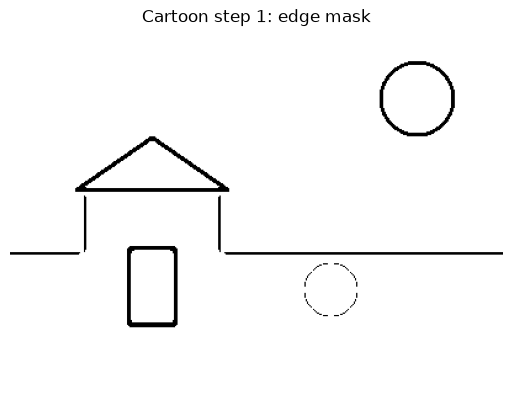

In [2]:
img = cv2.imread("../assets/test_image.png")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
smooth_gray = cv2.medianBlur(gray, 5)
edges = cv2.adaptiveThreshold(smooth_gray, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, 9, 9)
show(edges, "Cartoon step 1: edge mask")

## Project 1 - Cartoonifier: flat colours and combine

Step 2 flattens colours with repeated bilateral filtering (it smooths while keeping edges, notebook 06). Colour quantisation with k-means flattens further. Step 3 keeps the flat colours only where the edge mask is white.

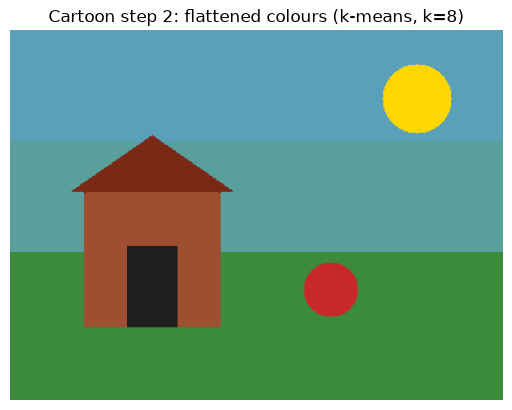

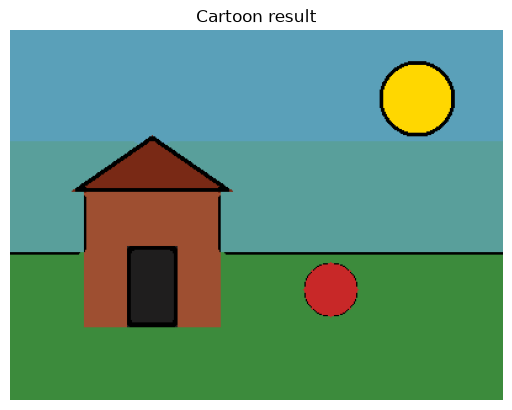

In [3]:
colour = img.copy()
for _ in range(3):
    colour = cv2.bilateralFilter(colour, 9, 75, 75)
data = colour.reshape(-1, 3).astype(np.float32)
_, labels, centres = cv2.kmeans(data, 8, None, (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 20, 1.0), 3, cv2.KMEANS_PP_CENTERS)
flat_colour = centres[labels.ravel()].reshape(colour.shape).astype(np.uint8)
cartoon = cv2.bitwise_and(flat_colour, flat_colour, mask=edges)
show(flat_colour, "Cartoon step 2: flattened colours (k-means, k=8)")
show(cartoon, "Cartoon result")

## Project 2 - Face blur: detect, then blur the region

Privacy tools blur or pixelate faces automatically: detect with the Haar cascade (notebook 14), then replace each face region with a strong Gaussian blur or pixel blocks. On our synthetic drawing the cascade may find no face - so the region step is also demonstrated on a fixed example region, clearly labelled as such.

In [4]:
face_img = cv2.imread("../assets/face_test.png")
cascade = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")
faces = cascade.detectMultiScale(cv2.cvtColor(face_img, cv2.COLOR_BGR2GRAY), 1.1, 5, minSize=(30, 30))
print("Faces detected:", len(faces))
demo_regions = [tuple(f) for f in faces] if len(faces) else [(45, 45, 150, 150)]
print("Regions to blur:", demo_regions, "(fixed demo region used because the drawing was not detected)")

Faces detected: 0
Regions to blur: [(45, 45, 150, 150)] (fixed demo region used because the drawing was not detected)


## Project 2 - Face blur: Gaussian blur vs pixelation

Gaussian blur with a kernel proportional to the box size hides identity while looking smooth. Pixelation (shrink then enlarge with nearest-neighbour) is the classic mosaic look. Both destroy the original pixels in the output - for real privacy, never save the unblurred copy alongside.

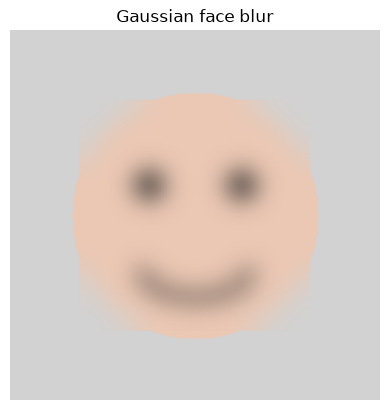

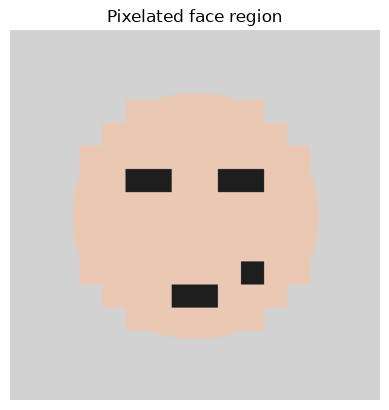

In [5]:
out_blur = face_img.copy()
out_pix = face_img.copy()
for (x, y, w, h) in demo_regions:
    roi = out_blur[y:y + h, x:x + w]
    out_blur[y:y + h, x:x + w] = cv2.GaussianBlur(roi, (51, 51), 0)
    small = cv2.resize(out_pix[y:y + h, x:x + w], (10, 10), interpolation=cv2.INTER_LINEAR)
    out_pix[y:y + h, x:x + w] = cv2.resize(small, (w, h), interpolation=cv2.INTER_NEAREST)
show(out_blur, "Gaussian face blur")
show(out_pix, "Pixelated face region")

## Project 3 - Gesture basics: skin mask and hand contour

Classic gesture recognition starts with a skin-colour mask in HSV or YCrCb, keeps the largest contour (the hand), and analyses its shape. Our 'hand' is a synthetic skin-toned blob with finger-like protrusions drawn on a plain background.

Hand contour area: 15411.0


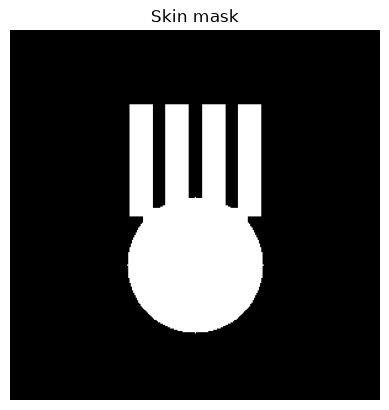

In [6]:
scene = np.full((300, 300, 3), 60, np.uint8)
skin_bgr = (140, 180, 220)
cv2.circle(scene, (150, 190), 55, skin_bgr, -1)                    # palm
for dx in (-44, -15, 15, 44):                                       # fingers
    cv2.rectangle(scene, (150 + dx - 9, 60), (150 + dx + 9, 150), skin_bgr, -1)
ycrcb = cv2.cvtColor(scene, cv2.COLOR_BGR2YCrCb)
skin_mask = cv2.inRange(ycrcb, np.array([0, 130, 80]), np.array([255, 175, 130]))
skin_mask = cv2.morphologyEx(skin_mask, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))
cs, _ = cv2.findContours(skin_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
hand = max(cs, key=cv2.contourArea)
print("Hand contour area:", cv2.contourArea(hand))
show(skin_mask, "Skin mask")

## Project 3 - Gesture basics: hull defects and finger counting idea

The gaps between fingers appear as convexity defects: places where the contour dips far inside its convex hull. Counting deep defects + 1 estimates raised fingers. Real hands under real lighting are much harder - changing light breaks colour masks, which is why modern gesture systems use learned hand-landmark models. The classic pipeline is still the right way to learn the geometry.

Deep convexity defects: 1 -> estimated raised fingers: 2


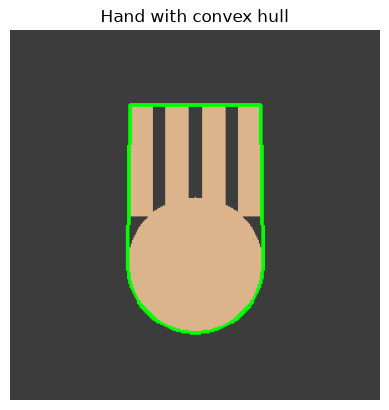

In [7]:
hull_idx = cv2.convexHull(hand, returnPoints=False)
defects = cv2.convexityDefects(hand, hull_idx)
deep = 0
if defects is not None:
    for d in defects[:, 0]:
        depth = d[3] / 256.0
        if depth > 18:
            deep += 1
print("Deep convexity defects:", deep, "-> estimated raised fingers:", deep + 1 if deep else 1)
out = scene.copy()
cv2.drawContours(out, [cv2.convexHull(hand)], -1, (0, 255, 0), 2)
show(out, "Hand with convex hull")

## Key Points

- Cartoon = adaptive-threshold edges + bilateral/k-means flat colours, combined by mask.
- K-means colour quantisation (here k=8) is what makes colours look truly flat.
- Face privacy = detect, then blur or pixelate the region; never keep the original beside it.
- If a detector finds nothing, say so and label any demo region as fixed - never fake detections.
- Gesture basics = skin mask (YCrCb) -> largest contour -> hull defects -> finger estimate.
- Colour-mask gestures break under changing light; learned landmark models are the modern answer.

## Mini Task

1. Cartoonifier: try k=5 and k=12 in the k-means step and describe which looks more like a cartoon.
2. Face blur: pixelate with a 6x6 grid instead of 10x10 - which hides identity better?
3. Gesture: remove one finger rectangle from the synthetic hand and check how the defect count changes.